# IND320 — Dashboard basics

Reservoir data analysis for the first compulsory hand-in. The source file is the course's `D2Dbook/data/reservoirs.csv`.

## Project links

- Public GitHub repository: https://github.com/yaksh-git/ind320-dashboard-basics-yaksh-git
- Streamlit app: https://ind320-dashboard-basics-yaksh-git.streamlit.app/

## 1. Load and rename the data

The source contains nine geographic series for each reporting week. For line plots, this notebook uses the supplied Norway total (`NO`, area `0`) so that each line represents one consistent area. The full imported data remains available in `data`.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Keep the CSV in the same folder as this notebook.
csv_path = Path('reservoirs.csv')
data = pd.read_csv(csv_path)

# Translate all source headers once; use these names in later cells.
column_names = {
    'dato_Id': 'date',
    'omrType': 'area_type',
    'omrnr': 'area_number',
    'iso_aar': 'iso_year',
    'iso_uke': 'iso_week',
    'fyllingsgrad': 'fill_level',
    'kapasitet_TWh': 'capacity_twh',
    'fylling_TWh': 'stored_energy_twh',
    'neste_Publiseringsdato': 'next_publication_date',
    'fyllingsgrad_forrige_uke': 'previous_week_fill_level',
    'endring_fyllingsgrad': 'fill_level_change',
}
data = data.rename(columns=column_names)
data['date'] = pd.to_datetime(data['date'], errors='coerce')
data = data.sort_values(['date', 'area_type', 'area_number']).reset_index(drop=True)
national = data.loc[(data['area_type'] == 'NO') & (data['area_number'] == 0)].copy()
print(f'{len(data):,} rows, {len(data.columns)} columns')
print(f'{national.date.min():%Y-%m-%d} to {national.date.max():%Y-%m-%d}')

14,877 rows, 11 columns
1995-01-08 to 2026-09-06


## 2. Inspect the contents

Show representative rows, column types, missing values and numeric summaries. This is more useful than printing all 14,877 rows.

In [2]:
# Show useful fields from the beginning and end of the sorted source.
preview_columns = ['date', 'area_type', 'area_number', 'fill_level',
                   'capacity_twh', 'stored_energy_twh']
display(data[preview_columns].head(10))
display(data[preview_columns].tail(10))
display(pd.DataFrame({'dtype': data.dtypes.astype(str), 'missing': data.isna().sum()}))
# A compact numeric summary fits both the notebook and PDF page.
display(data.select_dtypes(include='number').describe().T[['count', 'mean', 'std', 'min', 'max']])

,date,area_type,area_number,fill_level,capacity_twh,stored_energy_twh
0,1995-01-08,EL,1,0.621467,6.003264,3.730831
1,1995-01-08,EL,2,0.630947,34.043590,21.479713
2,1995-01-08,EL,3,0.602376,8.920932,5.373754
3,1995-01-08,EL,4,0.558864,21.079208,11.780413
4,1995-01-08,EL,5,0.616448,17.390587,10.720388
5,1995-01-08,NO,0,0.608274,87.437580,53.185986
6,1995-01-08,VASS,1,0.636038,36.044464,22.925638
7,1995-01-08,VASS,2,0.608856,23.237715,14.148431
8,1995-01-08,VASS,3,0.566906,28.155403,15.961480
9,1995-01-15,EL,1,0.583100,6.003264,3.500502


,date,area_type,area_number,fill_level,capacity_twh,stored_energy_twh
14867,2026-08-30,VASS,3,0.827718,28.155403,23.304743
14868,2026-09-06,EL,1,0.725045,6.003264,4.352634
14869,2026-09-06,EL,2,0.460863,34.043590,15.689445
14870,2026-09-06,EL,3,0.632579,8.920932,5.643190
14871,2026-09-06,EL,4,0.902762,21.079208,19.029512
14872,2026-09-06,EL,5,0.638898,17.390587,11.110812
14873,2026-09-06,NO,0,0.636054,87.437580,55.615055
14874,2026-09-06,VASS,1,0.570397,36.044464,20.559645
14875,2026-09-06,VASS,2,0.516978,23.237715,12.013381
14876,2026-09-06,VASS,3,0.826252,28.155403,23.263466


,dtype,missing
date,datetime64[ns],0
area_type,object,0
area_number,int64,0
iso_year,int64,0
iso_week,int64,0
fill_level,float64,0
capacity_twh,float64,0
stored_energy_twh,float64,0
next_publication_date,object,0
previous_week_fill_level,float64,0


,count,mean,std,min,max
area_number,14877.0,2.333333,1.490762,0.000000,5.000000
iso_year,14877.0,2010.346038,9.146696,1995.000000,2026.000000
iso_week,14877.0,26.405929,15.017910,1.000000,53.000000
fill_level,14877.0,0.618852,0.214850,0.055160,1.020072
capacity_twh,14877.0,29.145860,22.739070,6.003264,87.437580
stored_energy_twh,14877.0,18.139713,15.966211,0.331142,84.544820
previous_week_fill_level,14877.0,0.618890,0.214843,0.055160,1.020037
fill_level_change,14877.0,-0.000038,0.031385,-0.242484,0.336623


## 3. Plot every column separately

Numeric values are shown as time series for Norway total. The date field is shown as counts by year, geographic identifiers as bar charts, and the publication field as a valid/missing count. The source uses year `0001` to mean that no next publication date is supplied.

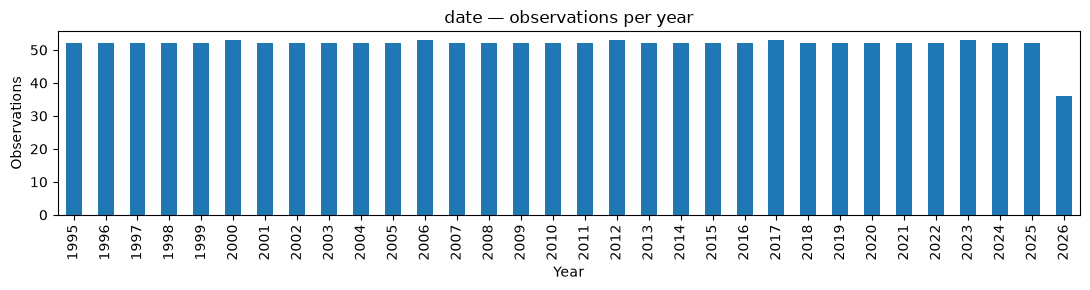

In [3]:
# Plot the date column as number of national observations per year.
counts = national['date'].dt.year.value_counts().sort_index()
ax = counts.plot.bar(figsize=(11, 3), title='date — observations per year')
ax.set(xlabel='Year', ylabel='Observations')
plt.tight_layout(); plt.show()

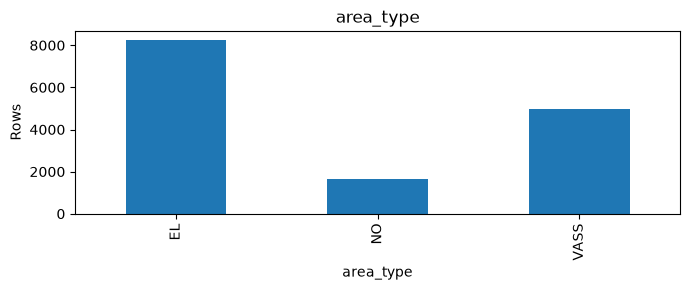

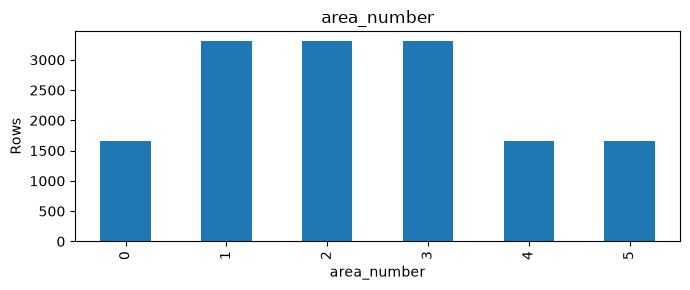

In [4]:
# Plot both geographic identifier columns using all records.
for column in ['area_type', 'area_number']:
    ax = data[column].value_counts().sort_index().plot.bar(figsize=(7, 3), title=column)
    ax.set(xlabel=column, ylabel='Rows')
    plt.tight_layout(); plt.show()

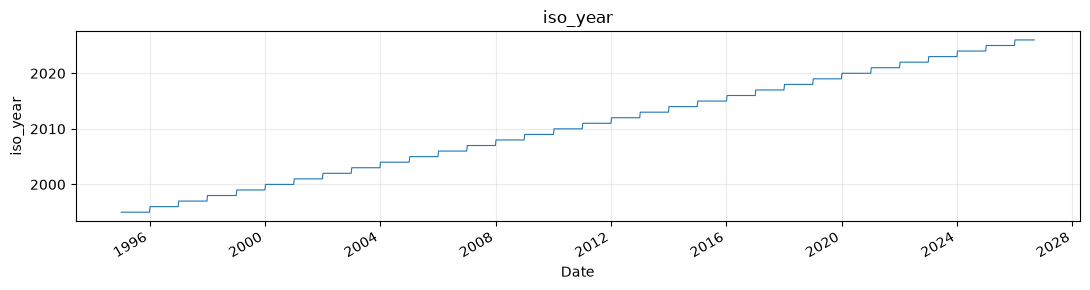

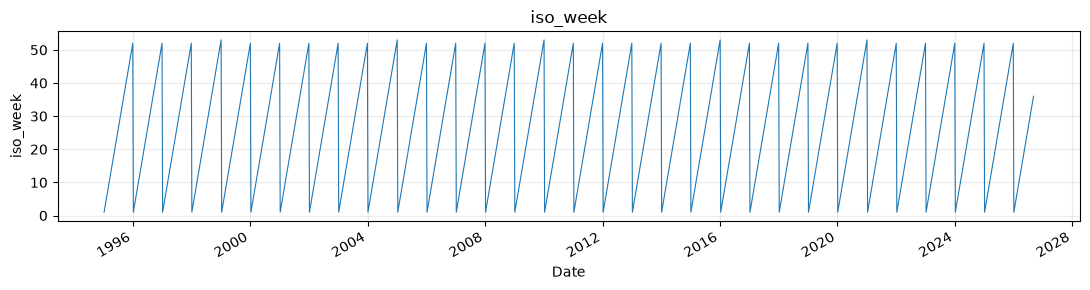

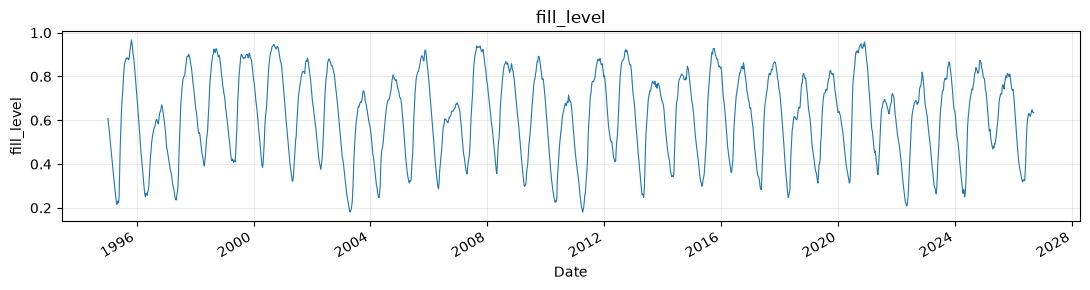

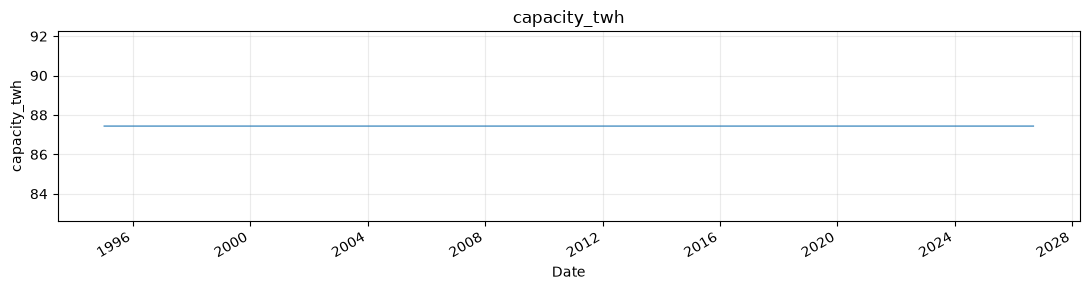

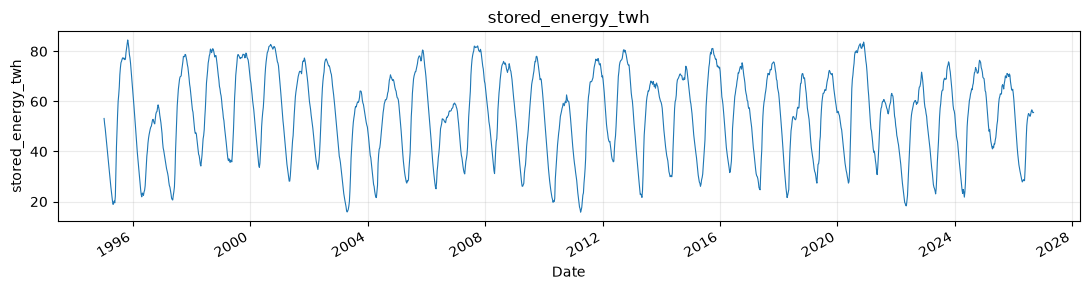

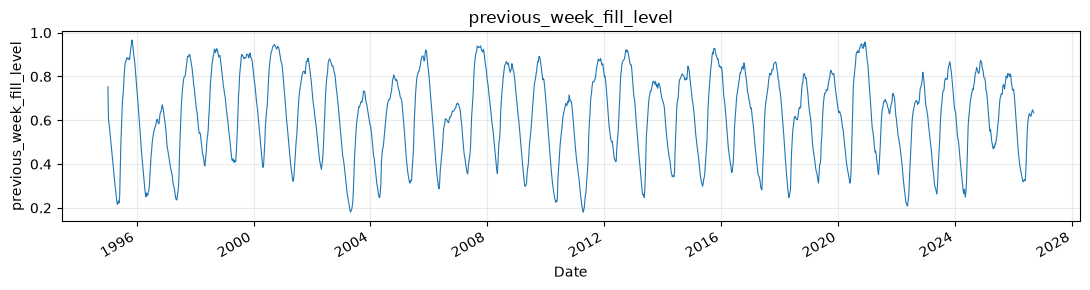

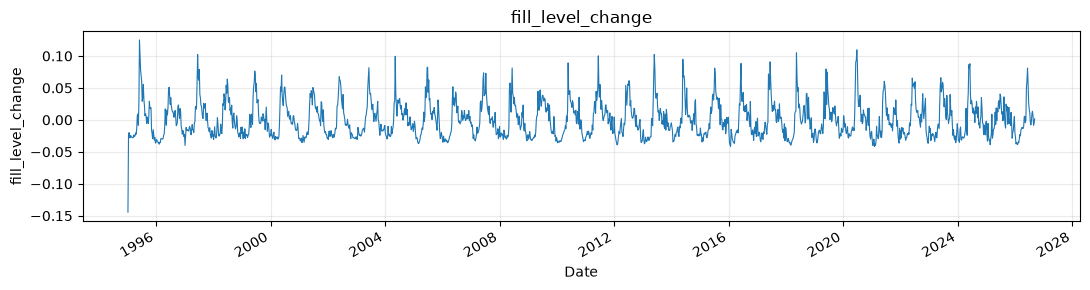

In [5]:
# Plot each numeric column separately for one coherent geographic series.
numeric_columns = ['iso_year', 'iso_week', 'fill_level', 'capacity_twh',
                   'stored_energy_twh', 'previous_week_fill_level', 'fill_level_change']
for column in numeric_columns:
    fig, ax = plt.subplots(figsize=(11, 3))
    ax.plot(national['date'], national[column], linewidth=0.8)
    ax.set(title=column, xlabel='Date', ylabel=column)
    ax.grid(alpha=0.25)
    fig.autofmt_xdate()
    plt.tight_layout(); plt.show()

C:\Users\yaksh\AppData\Local\Temp\ipykernel_3672\3448080836.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  next_date = pd.to_datetime(data['next_publication_date'], errors='coerce')


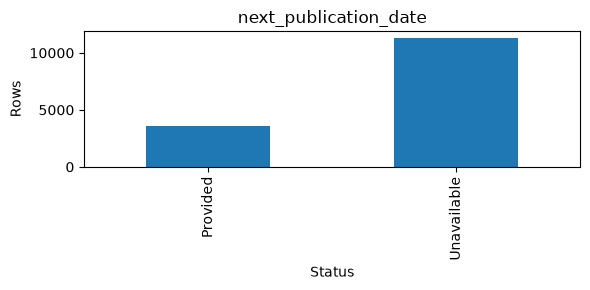

In [6]:
# Year 0001 is outside pandas' datetime range and means no usable date.
next_date = pd.to_datetime(data['next_publication_date'], errors='coerce')
publication_counts = pd.Series({'Provided': next_date.notna().sum(),
                                'Unavailable': next_date.isna().sum()})
ax = publication_counts.plot.bar(figsize=(6, 3), title='next_publication_date')
ax.set(xlabel='Status', ylabel='Rows')
plt.tight_layout(); plt.show()

## 4. Plot all numeric columns together

The columns have different units and ranges. Min–max scaling maps each nonconstant column to 0–1, making its shape comparable without implying that the original units are the same. This plot shows relative changes, not absolute reservoir levels.

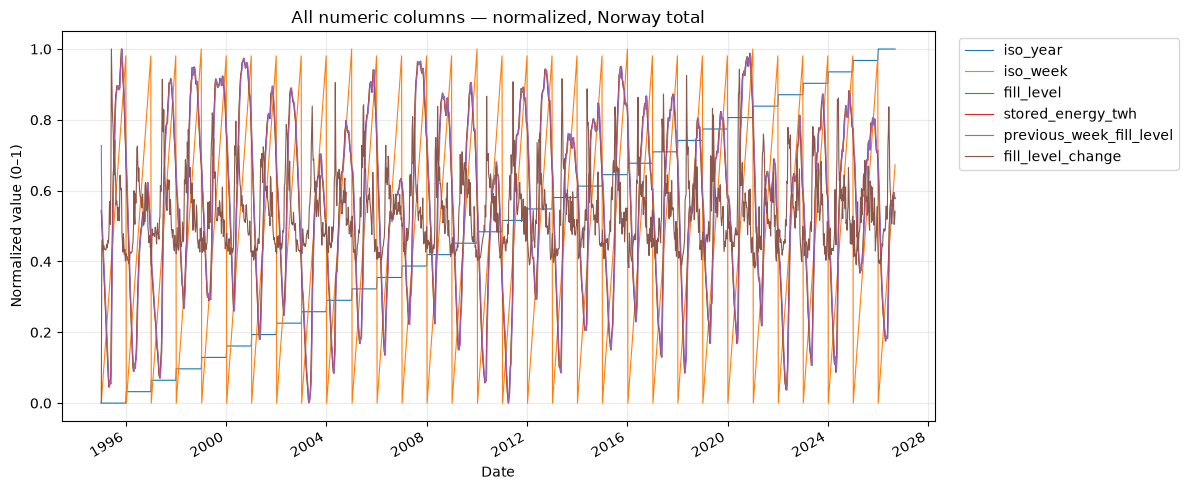

In [7]:
# Normalize the national series column by column; omit constants.
values = national[numeric_columns]
ranges = values.max() - values.min()
varying = ranges[ranges > 0].index
scaled = (values[varying] - values[varying].min()) / ranges[varying]
fig, ax = plt.subplots(figsize=(12, 5))
for column in varying:
    ax.plot(national['date'], scaled[column], linewidth=0.8, label=column)
ax.set(title='All numeric columns — normalized, Norway total',
       xlabel='Date', ylabel='Normalized value (0–1)')
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1))
ax.grid(alpha=0.25)
fig.autofmt_xdate()
plt.tight_layout(); plt.show()

## 5. AI usage

I used OpenAI Codex to help create the initial notebook and Streamlit app, translate column names, choose readable plots, and check the code against the assignment. The resulting files were run in local tests. I will review the final app and notebook before submission. **Edit this statement to match what you personally did before handing it in.**

## 6. Arbeidslogg (utkast – kontroller og tilpass før innlevering)

Arbeidet med første del av IND320 startet med å gå gjennom kravene i Canvas og finne datafilen `reservoirs.csv` i faglærerens GitHub-repo. Jeg brukte OpenAI Codex som programmeringshjelp til å lage et første utkast til både Jupyter Notebook og Streamlit-appen. Bruken av AI er beskrevet separat over. Før innlevering må jeg selv kontrollere at denne loggen gjenspeiler det jeg faktisk har gjort, og legge til erfaringene fra siste gjennomgang, publisering og skjermopptak.

I notebooken blir CSV-filen lest med Pandas, og alle de norske kolonnenavnene blir oversatt til engelske navn som er lettere å bruke videre i koden. Datasettet inneholder flere geografiske serier for hver uke. Derfor brukes serien for Norge totalt når verdier vises over tid, mens hele datasettet brukes når kategoriene skal telles. Jeg viser de første og siste radene, datatyper, manglende verdier og en statistisk oppsummering. Dette gir et mer lesbart inntrykk av innholdet enn å skrive ut alle radene. Hver kolonne får sin egen figur. For kolonner med tall brukes tidsserier, mens kategorier og datoer vises på en måte som passer datatypen. Til slutt vises tallkolonnene sammen etter min–maks-normalisering, siden de har ulike enheter og skalaer. Alle kodecellene ble kjørt og kontrollert uten feil, slik at tabeller og figurer er lagret i notebooken.

Streamlit-appen er bygget som fire separate sider med navigasjon i sidepanelet. Startsiden forklarer prosjektet, tabellsiden har én rad per CSV-kolonne og små linjediagrammer for den første måneden, og plotsiden lar brukeren velge kolonne og et intervall av måneder. Den fjerde siden er foreløpig en enkel plassholder, slik oppgaven åpner for. Data leses fra en lokal CSV-fil og mellomlagres med Streamlits cache-funksjon. Det var viktig å skille mellom den fullstendige tabellen og den nasjonale tidsserien; ellers kunne kurven ha hoppet mellom ulike geografiske områder. Alle fire sidene ble kjørt i en lokal app-test. Jeg testet også et konkret kolonnevalg og et månedsintervall, og tabellen viste elleve rader som forventet.

Prosjektfilene ble deretter lagt i et offentlig GitHub-repo, og Streamlit Cloud ble koblet til `app.py` på hovedgrenen. De faktiske lenkene står øverst i notebooken. Nettappen ble åpnet og kontrollert på alle fire sider etter publisering. Før levering gjenstår min egen gjennomlesning av notebook og PDF og et kort skjermopptak. Jeg må også justere formuleringer i denne loggen som ikke stemmer med min egen erfaring.
